# AgriScreen: is my vineyard drier than usual?

A winegrower near Condom (Gers, south-west France) wants one simple answer: **is my parcel unusual right now,
compared with its own history?** AgriScreen answers it with open Copernicus data and says how far each answer can be
trusted.

The card for each vineyard has three sentences:

1. **Soil in the area:** dry / near normal / wet (ERA5-Land model, about 9 km, compared with soil sensors).
2. **Your parcel:** the vegetation water index (Sentinel-2, short-wave infrared) below / within / above its own
   normal for this time of year, and how many vineyards nearby are in the same state.
3. **The area:** whether vineyard vegetation follows soil water. This sentence appears only if a pre-registered test
   confirms it. In the first run it did not, so the card hides it.

AgriScreen gives no irrigation advice and does not diagnose vine water stress: the satellite sees the whole parcel,
vines, inter-rows and soil together. Two attempts to flag places *inside* a parcel against their own history failed
their pre-registered tests, so the panel does not draw them (section 5).

Interactive panel: `docs/showcase/agriscreen_panel.html` · code and protocols:
[github.com/geoworldlook/agriscreen](https://github.com/geoworldlook/agriscreen).

In [1]:
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data published with the repository (no keys, no Earth Engine, no GPU needed)
DATA = next((p for p in ('docs/showcase', '../docs/showcase', '/content/agriscreen/docs/showcase') if os.path.isdir(p)), None)
if DATA is None and 'google.colab' in sys.modules:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/geoworldlook/agriscreen.git', '/content/agriscreen'], check=True)
    DATA = '/content/agriscreen/docs/showcase'
D = json.load(open(os.path.join(DATA, 'agriscreen_data.json'), encoding='utf-8'))
tests = pd.read_csv(os.path.join(DATA, 'w3b_tests.csv'))
dates = pd.to_datetime(D['dates'])
print(f"{len(D['map']['shapes'])} vineyards, {len(dates)} Sentinel-2 scene days {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")
print(f"Tests frozen on {D['freeze']}, protocol SHA-256 {D['protocol']}...")
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLORS = {'wb': '#7a4a0e', 'b': '#c08a3e', 'n': '#e9e6dc', 'a': '#5fa69b', 'wa': '#1f6a62', 'nd': '#f4f4f0'}
def zclass(z):
    if z is None or not np.isfinite(z): return 'nd'
    return 'wb' if z <= -1.5 else 'b' if z <= -1 else 'n' if z < 1 else 'a' if z < 1.5 else 'wa'
def layer(key):
    return pd.DataFrame({s: pd.Series(v, index=dates, dtype=float) for s, v in D['layers'][key].items()})
water = layer('water')
qc = [s for s, v in D['sites'].items() if v['qc_ok']]
soil = pd.Series(D['soil']['pct'], index=pd.to_datetime(D['soil']['dates']), dtype=float)
summer = soil[(soil.index.month >= 6) & (soil.index.month <= 9)]
soil_by_year = summer.groupby(summer.index.year).mean()   # ERA5-Land 0–100 cm percentile, June–September mean

15 vineyards, 329 Sentinel-2 scene days 2018-04-19 to 2026-10-14
Tests frozen on 2026-10-18, protocol SHA-256 f01b74a804b2...


## 1. Fifteen vineyards, each against its own history

Every vineyard in the study area (15 parcels, 0.7 to 4.1 ha) is measured inside a strip 20 m from its edge, so that
20 m infrared pixels do not mix in the neighbours. Two parcels are too small after that cut (fewer than 40 pixels);
they get no class.

For each scene, the index of a parcel is compared with the **same parcel in the previous five years**, within
±15 days of the calendar and on the same satellite orbit. The result is a z-score; −1 or lower counts as
“below its own normal”. By construction about one scene in six lands there even in an ordinary year, so a single
such scene is not unusual in itself. The map shows the latest scene.

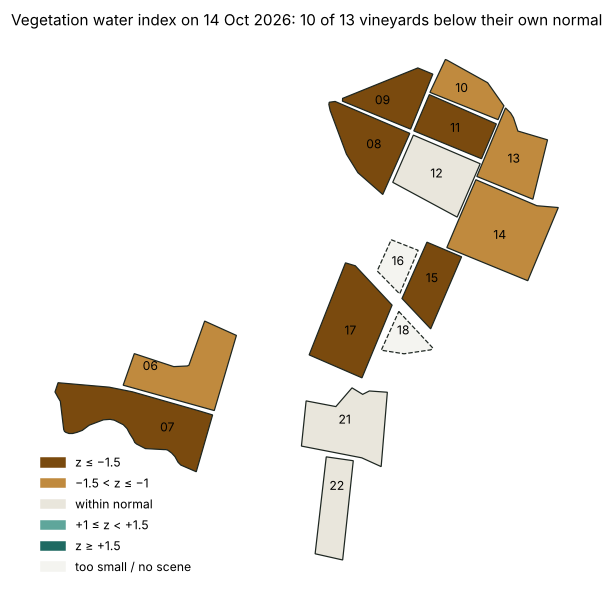

In [2]:
def polys(d):
    return [np.array([[float(a) for a in p.split(',')] for p in part.split('L')]) for part in d.strip('Z').split('ZM')]
last = dates.max()
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for s in D['map']['shapes']:
    z = water.loc[last, s['id']] if s['id'] in water else np.nan
    c = COLORS[zclass(z)] if s['id'] in qc else COLORS['nd']
    for xy in polys(s['d'].lstrip('M')):
        ax.fill(xy[:, 0], -xy[:, 1], color=c, ec='#1d2621', lw=0.8, ls='-' if s['id'] in qc else '--')
    ax.text(s['cx'], -s['cy'], f"{s['fid']:02d}", ha='center', va='center', fontsize=8)
ax.set_aspect('equal'); ax.axis('off')
n = sum(1 for s in qc if water.loc[last, s] <= -1)
ax.set_title(f"Vegetation water index on {last:%d %b %Y}: {n} of {water.loc[last, qc].notna().sum()} vineyards below their own normal", fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS[k], label=l) for k, l in (('wb', 'z ≤ −1.5'), ('b', '−1.5 < z ≤ −1'), ('n', 'within normal'),
          ('a', '+1 ≤ z < +1.5'), ('wa', 'z ≥ +1.5'), ('nd', 'too small / no scene'))], loc='lower left', fontsize=8, frameon=False)
plt.show()

## 2. Soil water in the area: compared with sensors in the ground

The soil sentence uses the ERA5-Land model (0–100 cm) and the ASCAT soil water index from Copernicus. Both were
compared with soil sensors at three stations — Condom (ISMN, 136 m from vineyard 06), Auradé in the Gers and
Lusignan (ICOS) — under a protocol registered before computing. No pass threshold was set. The agreement is
moderate: the anomaly correlation is about 0.57 at Condom and Auradé (0.68 at Lusignan, on 35-day anomalies), and
the model puts the day in the same dry / normal / wet class as the sensor on 55–65% of days. The table is the one
shown in the panel; the status column says what kind of check each line had.

In [3]:
trust = pd.DataFrame(D['trust'])[['what', 'against', 'result', 'status']]
display(trust)

what,against,result,status
"Soil moisture 0–100 cm (ERA5-Land model, ~9 km)","in situ soil sensors at 3 stations (ISMN Condom, ICOS Auradé and Lusignan); no pass threshold was set","anomaly correlation Condom R 0.57; Auradé R 0.57; Lusignan R 0.68 (35-day anomalies); same dry/normal/wet class on 55%, 55%, 65% of days (moderate agreement)",checked
"Soil water index (ASCAT satellite, ~10 km)","in situ soil sensors at 3 stations (ISMN Condom, ICOS Auradé and Lusignan); no pass threshold was set","anomaly correlation Condom R 0.57; Auradé R 0.52; Lusignan R 0.53 (35-day anomalies); same dry/normal/wet class on 52%, 49%, 60% of days (moderate agreement)",checked
"Rainfall, 30-day sums (ERA5-Land)","rain gauge CONDOM (0 km, 173 m)",R 0.90,checked
Parcel vegetation water index: noise between scenes,pairs of scenes a few days apart without rain,"smallest clear change (MDC95): 1.0 z (same orbit), 1.1 z (different orbits)",descriptive
Parcel index: how often “below its own normal” appears,"all scenes June–September, 13 vineyards (expected 16%, 1 in 6)","28% [4–52%] of scenes; varies strongly between years, from 1% (2021) to 76% (2022); 14% on scenes with near-normal soil; no gross miscalibration detected (a weak test)",descriptive
Area vegetation follows soil water of the previous 30 days,"ISMN sensor at Condom, June–September 2018–2024 (pre-registered test)","ρ 0.55 [-0.02; 1.00]; mostly between years, not within a season",not confirmed
"4-band model (red, red-edge, NIR, SWIR) instead of the simple index","same test, years unseen by the model",no gain: Δρ -0.01 [-0.18; 0.16],not adopted
"Zones vs usual, greenness (NDVI): places weaker or stronger than usual, relative to the parcel","noise between scenes a few days apart without rain; how often zones appear when soil is normal (pre-registered W3c, 45708189b130…)",threshold 0.033 [0.025–0.041] from 689 scene pairs; cells in zones: 15.4% [9.9–20.9%] (days with normal soil; about 1% expected from noise); not shown: zones cover too much on days with normal soil (upper 20.9% > 5%),"experimental, not shown"
"Zones vs usual, water in vegetation (NDMI): places weaker or stronger than usual, relative to the parcel","noise between scenes a few days apart without rain; how often zones appear when soil is normal (pre-registered W3c, 45708189b130…)",threshold 0.023 [0.017–0.029] from 689 scene pairs; cells in zones: 15.5% [10.3–20.6%] (days with normal soil; about 1% expected from noise); not shown: noise (upper MDC95 0.029) is not below half the typical spread within a parcel (0.025); zones cover too much on days with normal soil (upper 20.6% > 5%),"experimental, not shown"
"Lowest in N years, greenness (NDVI): a 30 m place against the same month in its last 5 years","how often “lowest / highest in N years” occurs vs chance 1/(N+1) (pre-registered W3d, 599a381bb6d1…)",lowest 0.49 [0.00–1.92] × chance; highest 1.16 [0.00–3.23] × chance (months with normal soil); not shown: “lowest in N years” not confirmed to be as rare as chance (upper bound 1.92 × chance > 1.5); “highest in N years” not confirmed to be as rare as chance (upper bound 3.23 × chance > 1.5),"experimental, not shown"


## 3. The parcel index: water in the vegetation

The index averages two short-wave infrared indices that react to water in leaves (NDMI and CRSWIR; Ceccato et al.
2001). It sees the whole parcel, so it moves together with greenness and reacts mostly to stronger deficits.

The two seasons below are the wettest and one of the driest summers in the archive (ERA5-Land soil percentile in
June–September about 95 in 2024 and 14 in 2022). In 2024 few scenes fall below their own normal; in 2022 most do,
and the vineyards move together. That is why the card also says how many vineyards nearby are in the same state.

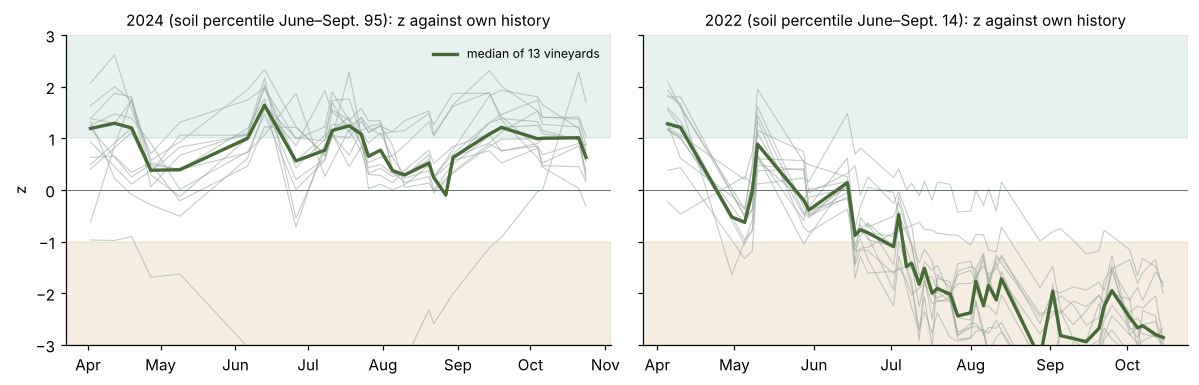

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, year in zip(axes, (2024, 2022)):
    w = water[(water.index.year == year)][qc]
    for s in qc:
        v = w[s].dropna()
        ax.plot(v.index, v.values, color='#9aa89f', lw=0.7, alpha=0.6)
    med = w.median(axis=1).dropna()
    ax.plot(med.index, med.values, color='#466b35', lw=2.2, label=f'median of {len(qc)} vineyards')
    ax.axhspan(-3, -1, color=COLORS['b'], alpha=0.15); ax.axhspan(1, 3, color=COLORS['a'], alpha=0.15)
    ax.axhline(0, color='#5d6a62', lw=0.6); ax.set_ylim(-3, 3)
    ax.set_title(f'{year} (soil percentile June–Sept. {soil_by_year.get(year, np.nan):.0f}): z against own history', fontsize=10)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b'))
axes[0].set_ylabel('z'); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Pre-registered tests and their results

The rules and the pass criteria were written down and hashed (SHA-256) before any number was computed, so they could
not be tuned after seeing the results. Only two tests decide something; the rest is reported as description.

- **T1 calibration (descriptive):** how often the class “below its own normal” appears (expected about 16%).
- **T2 noise (descriptive):** how large a change between two close scenes must be to stand out from noise.
- **T3 (decides sentence 3):** does the median of 12 vineyards follow the soil sensor at Condom over the previous
  30 days? Criterion: the lower bound of a 95% interval (jackknife by year) above zero.
- **4-band model (decides the index):** does a model of red, red-edge, NIR and SWIR bands, trained on the sensor,
  beat the simple index on years it has not seen?

test,value,95% interval,n,years,decides,verdict
"T1 share of “below normal” (13 vineyards, June–Sept.)",0.28,[0.04; 0.52],2469,2018-2026,False,no gross miscalibration (weak test)
"T2 smallest clear change, same orbit (z)",1.03,[0.59; 1.47],638,2019-2026,False,
"T2 smallest clear change, different orbits (z)",1.12,[0.77; 1.46],799,2019-2026,False,
T3 vegetation vs soil sensor (ρ),0.55,[-0.02; 1.00],140,2018-2024,True,not met (inconclusive)
4-band model gain over the simple index (Δρ),-0.01,[-0.18; 0.16],140,2018-2024,True,not adopted


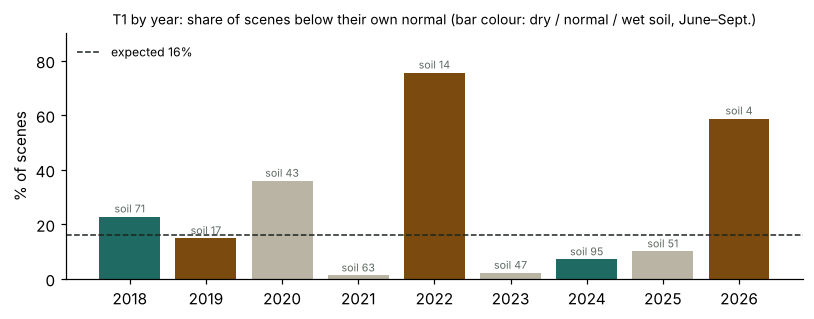

In [5]:
keys = {'t1_main': 'T1 share of “below normal” (13 vineyards, June–Sept.)', 't2_g5': 'T2 smallest clear change, same orbit (z)',
        't2_g13': 'T2 smallest clear change, different orbits (z)', 't3_main': 'T3 vegetation vs soil sensor (ρ)',
        'p7_accept': '4-band model gain over the simple index (Δρ)'}
k = tests[tests['key'].isin(keys)].set_index('key').loc[list(keys)]
res = pd.DataFrame({'test': [keys[i] for i in k.index], 'value': k['value'].round(2), '95% interval': [f"[{a:.2f}; {b:.2f}]" for a, b in zip(k['ci_low'], k['ci_high'])],
                    'n': k['n'], 'years': k['period'], 'decides': k['criterion'], 'verdict': k['verdict'].fillna('')})
res['verdict'] = res['verdict'].replace({'niespełnione (nierozstrzygnięty)': 'not met (inconclusive)', 'nieprzyjęty': 'not adopted',
                                         'nie wykryto grubego rozkalibrowania': 'no gross miscalibration (weak test)'})
display(res.reset_index(drop=True))
yr = tests[(tests['segment'] == 'T1') & tests['subset'].str.fullmatch(r'rok \d{4}')]
years = yr['subset'].str[4:].astype(int)
fig, ax = plt.subplots(figsize=(7.5, 3))
pct = soil_by_year.reindex(years).to_numpy()
ax.bar(years.astype(str), 100 * yr['value'], color=[COLORS['wb'] if p <= 30 else COLORS['wa'] if p >= 70 else '#b9b4a4' for p in pct])
for x, v, p in zip(years.astype(str), 100 * yr['value'], pct):
    ax.text(x, v + 1.5, f'soil {p:.0f}', ha='center', fontsize=7, color='#5d6a62')
ax.axhline(15.9, color='#1d2621', ls='--', lw=1, label='expected 16%'); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_ylabel('% of scenes'); ax.set_ylim(0, 90)
ax.set_title('T1 by year: share of scenes below their own normal (bar colour: dry / normal / wet soil, June–Sept.)', fontsize=9)
plt.tight_layout(); plt.show()

The yearly pattern is not tidy: 2019 had dry soil and few low scenes, 2020 near-normal soil and many. Split by the
soil on the day of each scene instead of by year, the picture is clearer. This split was made **after** the tests,
so it is exploratory and decides nothing.

exploratory, computed after the pre-registered tests; share of June–September scenes with z ≤ −1 by soil class on the scene day (ERA5-Land 0–100 cm percentile)


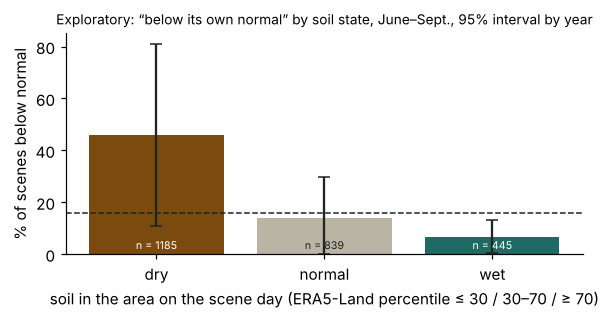

In [6]:
ex = pd.DataFrame(D['explore']['t1_by_soil']['rows'])
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(ex['soil'], 100 * ex['share'], color=[COLORS['wb'], '#b9b4a4', COLORS['wa']],
       yerr=[100 * (ex['share'] - ex['ci_low']), 100 * (ex['ci_high'] - ex['share'])], capsize=4, ecolor='#1d2621')
for i, r in ex.iterrows():
    ax.text(i, 2, f"n = {r['n']}", ha='center', fontsize=7, color='white' if r['soil'] != 'normal' else '#1d2621')
ax.axhline(15.9, color='#1d2621', ls='--', lw=1)
ax.set_ylabel('% of scenes below normal'); ax.set_xlabel('soil in the area on the scene day (ERA5-Land percentile ≤ 30 / 30–70 / ≥ 70)')
ax.set_title('Exploratory: “below its own normal” by soil state, June–Sept., 95% interval by year', fontsize=9)
plt.tight_layout(); plt.show()
print(D['explore']['t1_by_soil']['note'])

## 5. What we learned

- **The parcel index reacts to dry soil; its calibration is only loosely tested.** Over all June–September scenes
  the class “below its own normal” appears in 28% [4; 52] of scenes against 16% expected. The interval is wide because
  years differ so much (1% in 2021, 76% in 2022). On scenes with near-normal soil it is 14% [0; 30], but the protocol
  warns that this subset favours low values. The test found no gross miscalibration, and it is a weak test.
- **Noise between scenes is about 1 z.** Two clear scenes a few days apart without rain differ by less than about
  1 z in 95% of cases (MDC95), so smaller changes are not reported as a change.
- **Sentence 3 stays hidden.** Vineyard vegetation and the soil sensor agree mostly between years (ρ of seasonal
  means 0.64, seven seasons) but not within a season (0.06). The main test gave ρ = 0.55 with an interval from −0.02 to
  1.00: just below the criterion, as the power simulation predicted with only seven seasons.
- **More bands did not help.** The 4-band model did no better than the simple index (Δρ −0.01 [−0.18; 0.16]) and
  failed in the dry year 2022. It stays as the baseline for a future unmixing of vines and inter-rows.
- **Earlier numbers were higher.** A previous experiment compared each scene with a normal from all other years,
  including later ones, with a different reference and z-score. With the causal normal used now, the agreement with
  the sensor on the same days fell from 0.57 to 0.44; better sensor quality control brought it back to about 0.5.
  Several things changed at once, so the drop cannot be put down to the later years alone.
- **Places inside a parcel: two attempts, both failed.** Zones “weaker than usual” (W3c) would light up about 15% of
  the parcel area on days with normal soil (limit 5%). “Lowest in five years” for 30 m squares (W3d) could not be
  shown to be as rare as chance with only four years of normal-soil months. Neither is drawn on the map; both will
  be re-tested after the 2027 season with the same rules.

The next fair test needs new data: the 2027 season, with the same registered rules.

In [7]:
c = D['cards'][D['main_site']]
print(f"Card for vineyard 06, latest scene {c['date']}:")
for i, s in enumerate(c['sentences'], 1):
    print(f'  {i}. {s}')
for s in c['notes']:
    print(f'  Note: {s}')

Card for vineyard 06, latest scene 2026-10-14:
  1. Soil in the area (~10 km, ERA5-Land model): dry — percentile 2 vs 1991–2020 (D4 on the US Drought Monitor percentile scale), as of 2026-10-06.
  2. Your parcel — vegetation water index (SWIR): below its own normal (z = -1.4), scene 2026-10-14; 10 of 13 vineyards in the area are in the same class. Previous scene: 2026-10-11, z = -0.8 (change not assessed: no threshold for this pair of scenes).
  Note: Outside the tested period (June–September).


**Data:** Copernicus Sentinel-2 L2A, ERA5-Land and CLMS Soil Water Index; reference sensors ISMN (SMOSMANIA,
Condom) and ICOS (Auradé, Lusignan); rain gauges Météo-France; vineyard register RPG (IGN). **Code, protocols and
results notes:** [github.com/geoworldlook/agriscreen](https://github.com/geoworldlook/agriscreen)
(`docs/evidence/karta_wynikow.md`, `docs/evidence/W3b_protokol_walidacji.md`, `docs/evidence/W3b_wyniki.md`).